# AI Forecast
### Обучение моделей для предсказания погоды в 2 самых крупных городах России.<br>

После обучения модели должны предсказывать вероятность дождя на следующий день для своего города.<br>
Погодные данные Москвы и Санкт-Петербурга за период с 2000 по 2026 получены на сайте: <a href=https://open-meteo.com/>open-meteo.com</a><br>


## Подключение библиотек
Переключите флаг on_kaggle для работы на сайте!

In [1]:
on_kaggle = False

In [2]:
import warnings

warnings.filterwarnings(
    "ignore",
    message=".*'transformers'.*package isn't installed.*",
    category=UserWarning
)

from pathlib import Path
import os

if on_kaggle:
    !pip install -U --pre lightautoml==0.4.2 -q 2>/dev/null
    for dirname, _, filenames in os.walk('/kaggle/input'):
        for filename in filenames:
            print(os.path.join(dirname, filename))
    import kagglehub
    
from lightautoml.automl.presets.tabular_presets import TabularAutoML, TabularUtilizedAutoML
from lightautoml.tasks import Task
from lightautoml.report.report_deco import ReportDeco, ReportDecoUtilized
from lightautoml.addons.tabular_interpretation import SSWARM

import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

import pickle

from time import gmtime, strftime
import datetime

'nlp' extra dependency package 'fasttext-numpy2' isn't installed. Look at README.md in repo 'LightAutoML' for installation instructions.
'nlp' extra dependency package 'nltk' isn't installed. Look at README.md in repo 'LightAutoML' for installation instructions.
'nlp' extra dependency package 'transformers' isn't installed. Look at README.md in repo 'LightAutoML' for installation instructions.


In [3]:
#Датасеты

#Погода в Москве 01.01.2000 – 31.12.2025
if on_kaggle:
     msk_dir = Path(kagglehub.dataset_download("e1gris/msk-weather"))
else:
    msk_dir = "datasets/msk.csv"

#Погода в Санкт-Петербурге 01.01.2000 – 31.12.2025
if on_kaggle:
    spb_dir = Path(kagglehub.dataset_download("e1gris/spb-weather"))
else:
    spb_dir = "datasets/spb.csv"

In [4]:
msk_df = pd.read_csv(msk_dir)
spb_df = pd.read_csv(spb_dir)
for x in msk_df.columns:
    print(x)

msk_df.sample(3)

time
temperature_2m_mean (°C)
surface_pressure_mean (hPa)
rain_sum (mm)
wind_speed_10m_mean (km/h)
wind_direction_10m_dominant (°)


,time,temperature_2m_mean (°C),surface_pressure_mean (hPa),rain_sum (mm),wind_speed_10m_mean (km/h),wind_direction_10m_dominant (°)
8845,2024-03-20,-2.8,1006.8,0.0,4.8,103
8989,2024-08-11,16.5,986.3,7.6,13.5,280
7047,2019-04-18,5.7,1009.3,0.3,9.8,25


In [5]:
def count_mean(df, column_name):
    values = df[df[column_name] != 0.0][column_name].to_numpy()
    
    return values.mean()


In [6]:
def encode_by_mean(df, column_name, edge, mean = None):

    if mean is None:
        mean =  count_mean(df, column_name)

    df1 = df.copy()
    
    for i in range(df1.shape[0]):
        value = float(df1.loc[df1.index[i], column_name])
        if value == 0:
            continue
        elif value - mean > edge:
            df1.loc[df1.index[i], column_name] = 3
        elif value - mean < -edge:
            df1.loc[df1.index[i], column_name] = 1
        else:
            df1.loc[df1.index[i], column_name] = 2

    return (df1, mean)


def encode_data(df, means = None):
    df1 = df.copy()

    if means is None:
        df1, mean_rain = encode_by_mean(df1, "rain_sum (mm)", 1.5)
        df1, mean_pressure = encode_by_mean(df1, "surface_pressure_mean (hPa)", 4.2)
    else:
        df1, mean_rain = encode_by_mean(df1, "rain_sum (mm)", 1.5, means[0])
        df1, mean_pressure = encode_by_mean(df1, "surface_pressure_mean (hPa)", 4.2, means[1])

    column_name = "wind_speed_10m_mean (km/h)"
    for i in range(df1.shape[0]):
        value = float(df1.loc[df1.index[i], column_name])
        
        if value <= 1.6:
            df1.loc[df1.index[i], column_name] = 0
        elif value <= 19.3:
            df1.loc[df1.index[i], column_name] = 1
        elif value <= 38.6:
            df1.loc[df1.index[i], column_name] = 2
        else:
            df1.loc[df1.index[i], column_name] = 3
    
    column_name = "temperature_2m_mean (°C)"
    for i in range(df1.shape[0]):
        value = float(df1.loc[df1.index[i], column_name])
        
        if value <= -20:
            df1.loc[df1.index[i], column_name] = 0
        elif value <= -5:
            df1.loc[df1.index[i], column_name] = 1
        elif value < 5:
            df1.loc[df1.index[i], column_name] = 2
        elif value <= 10:
            df1.loc[df1.index[i], column_name] = 3
        elif value <= 20:
            df1.loc[df1.index[i], column_name] = 4
        else:
            df1.loc[df1.index[i], column_name] = 5

    column_name = "wind_direction_10m_dominant (°)"
    for i in range(df1.shape[0]):
        value = float(df1.loc[df1.index[i], column_name]) % 360
    
        if value < 30 or value >= 330:
            df1.loc[df1.index[i], column_name] = 0
        elif value < 60:
            df1.loc[df1.index[i], column_name] = 1
        elif value < 120:
            df1.loc[df1.index[i], column_name] = 2
        elif value < 150:
            df1.loc[df1.index[i], column_name] = 3
        elif value < 210:
            df1.loc[df1.index[i], column_name] = 4
        elif value < 240:
            df1.loc[df1.index[i], column_name] = 5
        elif value < 300:
            df1.loc[df1.index[i], column_name] = 6
        else:
            df1.loc[df1.index[i], column_name] = 7
    
    return [df1, [mean_rain, mean_pressure]]

In [7]:
def add_lags(df, max_lags, drop_time = True):
    df2 = df.copy()

    lags = {}

    for i in range(1, max_lags + 1):
        lags[f'rain_shift{i}'] = (
            df2['rain_sum (mm)'].shift(i)
        )

        lags[f'wind_dir_shift{i}'] = (
            df2['wind_direction_10m_dominant (°)'].shift(i)
        )

        lags[f'wind_speed_shift{i}'] = (
            df2['wind_speed_10m_mean (km/h)'].shift(i)
        )

        lags[f'pressure_shift{i}'] = (
            df2['surface_pressure_mean (hPa)'].shift(i)
        )

        lags[f'temperature_shift{i}'] = (
            df2['temperature_2m_mean (°C)'].shift(i)
        )

    lag_df = pd.DataFrame(lags, index=df2.index)

    df2 = pd.concat([df2, lag_df], axis=1)

    if drop_time:
        df2 = df2.drop(columns=["time"])
    else:
        df2["time"] = pd.to_datetime(df2["time"])
        df2["time"] = df2["time"].dt.day_of_year
    
    df2 = df2.drop(columns = ['wind_direction_10m_dominant (°)', 'wind_speed_10m_mean (km/h)', 'wind_direction_10m_dominant (°)', 'surface_pressure_mean (hPa)', 'temperature_2m_mean (°C)'])
    df2 = df2.dropna()
    df2 = df2.rename(columns={'rain_sum (mm)': 'target'})

    return df2

In [8]:
def do_test_split(df):
    size = df.shape[0]

    test = df.iloc[size//100 * 80:]
    df = df.iloc[:size//100 * 80]

    return [df, test]

In [9]:
def split_data(df):
    df = df.copy()
    
    target = df["target"]
    df = df.drop(columns=["target"])
    target = (target != 0).astype(int)

    X_train, X_val, y_train, y_val = train_test_split(
    df, 
    target, 
    test_size=0.2, 
    shuffle=False,      
    )

    return [X_train, X_val, y_train, y_val]

In [10]:
# size = df.shape[0]

# test = df.iloc[size//100 * 80:]
# df = df.iloc[:size//100 * 80]



In [11]:
def train_model(df, number_of_lags, cat = False, drop_time = True):
    
    df = df.copy()

    means = None

    if cat == True:
        df, means = encode_data(df)
        method = "Категориальный"
    else:
        method = "Оригинальные значения"

    df = add_lags(df, number_of_lags, drop_time)

    X_train, X_val, y_train, y_val = split_data(df)
    
    train_data = X_train.copy()
    train_data['target'] = y_train
    
    task = Task('binary')
    roles = {
        'target': "target",
    }
    N_THREADS = 8
    RANDOM_STATE = 42
    N_FOLDS = 3
    
    automl = TabularAutoML(
        task = task,
        timeout = 120,
        cpu_limit = N_THREADS,
        general_params={'use_algos': [['lgb']]},
        reader_params = {'n_jobs': N_THREADS, 'cv': N_FOLDS, 'random_state': RANDOM_STATE},
    )
    
    out_of_fold_predictions = automl.fit_predict(train_data, roles = roles, verbose = 0)
    
    val_predictions = automl.predict(X_val)
    probabilities = val_predictions.data[:, 0]
    
    threshold = 0.5
    binary_predictions = (probabilities > threshold).astype(int)
    
    f1 = f1_score(y_val, binary_predictions)

    return {"Model": automl, "number_of_lags": number_of_lags, "method": method, "f1": f1, "means": means}
    

In [12]:
def find_best_model(df, max_lags = 30, drop_time = True):
    best_model = {"f1": -1}
    history = {"cat": [], "orig": [], "lags": []}

    df = df.copy()
    df = do_test_split(df)[0]
    
    for number_of_lags in range(5, max_lags+1, 5):
    
        print(f"number_of_lags = {number_of_lags}")
        
        cat_model = train_model(df, number_of_lags, True, drop_time)
        orig_model = train_model(df, number_of_lags, False, drop_time)
    
        history["cat"].append(cat_model["f1"])
        history["orig"].append(orig_model["f1"])
        history["lags"].append(number_of_lags)
        
        if cat_model["f1"] > orig_model["f1"]:
            model = cat_model
        else:
            model = orig_model
    
        if model["f1"] > best_model["f1"]:
            best_model = model

    return [best_model, history] 
    

In [13]:
def do_final_test(df, best_model, drop_time = True):
    best_model_stats = best_model.copy()
    best_model_stats.pop("Model", None)
    best_model_stats.pop("means", None)
    print("valid model ", best_model_stats)

    df = df.copy()

    test = do_test_split(df)[1]

    means = None
    
    if best_model["method"] == "Категориальный":
        means = best_model["means"]
        test = encode_data(test, means)[0]
        
    
    test = add_lags(test, best_model["number_of_lags"], drop_time)
    
    y_test = test["target"]
    y_test = (y_test != 0).astype(int)
    
    X_test = test.drop(columns=["target"])
    
    val_predictions = best_model["Model"].predict(X_test)
    probabilities = val_predictions.data[:, 0]
    
    threshold = 0.5
    binary_predictions = (probabilities > threshold).astype(int)
    
    f1 = f1_score(y_test, binary_predictions)
    
    print("test f1 =",f1)
        

In [14]:
def draw_model_stats(history):
    plt.plot(history["lags"], history["cat"], label = "cat", color = "orange")
    plt.plot(history["lags"], history["orig"], label = "orig", color = "blue")
    
    plt.xlabel("number of lags")
    plt.ylabel("F1 Score")
    
    
    plt.legend()
    plt.grid()
    plt.show()

In [15]:
best_model, history = find_best_model(msk_df, max_lags = 30, drop_time = True)


number_of_lags = 5
number_of_lags = 10
number_of_lags = 15
number_of_lags = 20
number_of_lags = 25
number_of_lags = 30


valid model  {'number_of_lags': 5, 'method': 'Категориальный', 'f1': 0.7214035087719298}
test f1 = 0.6940427993059572


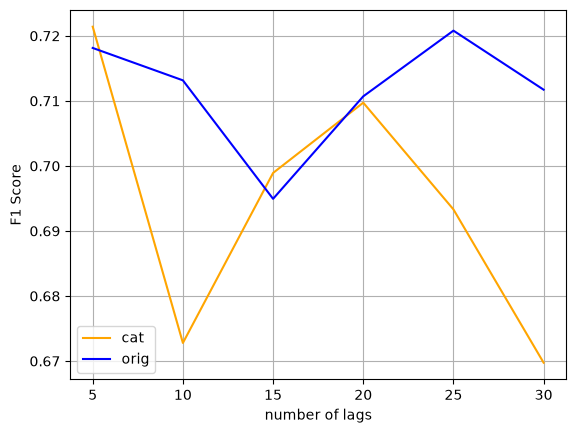

In [16]:
do_final_test(msk_df, best_model, True)

draw_model_stats(history)

In [17]:
best_model, history = find_best_model(spb_df)

number_of_lags = 5
number_of_lags = 10
number_of_lags = 15
number_of_lags = 20
number_of_lags = 25
number_of_lags = 30


valid model  {'number_of_lags': 5, 'method': 'Оригинальные значения', 'f1': 0.7300970873786408}
test f1 = 0.7158329035585353


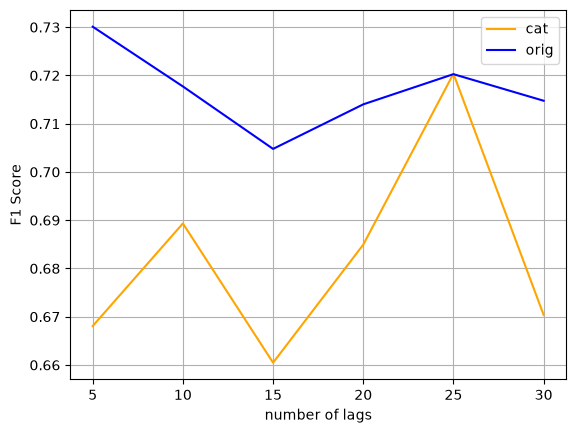

In [18]:
do_final_test(spb_df, best_model)

draw_model_stats(history)

In [19]:
best_model, history = find_best_model(msk_df, max_lags = 30, drop_time = False)

number_of_lags = 5
number_of_lags = 10
number_of_lags = 15
number_of_lags = 20
number_of_lags = 25
number_of_lags = 30


valid model  {'number_of_lags': 25, 'method': 'Категориальный', 'f1': 0.7207702888583218}
test f1 = 0.6979166666666666


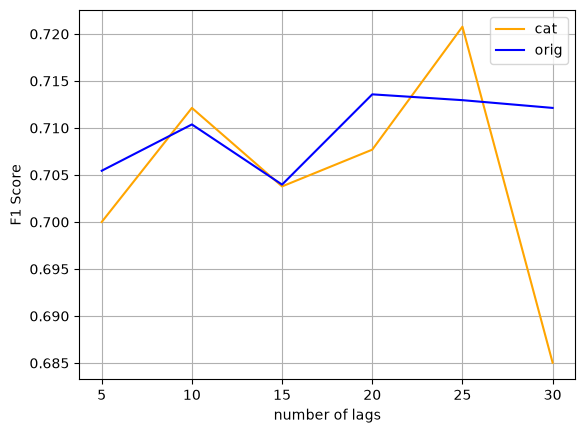

In [20]:
do_final_test(msk_df, best_model, drop_time = False)

draw_model_stats(history)

In [21]:
 best_model, history = find_best_model(spb_df, max_lags = 30, drop_time = False)

number_of_lags = 5
number_of_lags = 10
number_of_lags = 15
number_of_lags = 20
number_of_lags = 25
number_of_lags = 30


valid model  {'number_of_lags': 25, 'method': 'Категориальный', 'f1': 0.7207702888583218}
test f1 = 0.6522481502561184


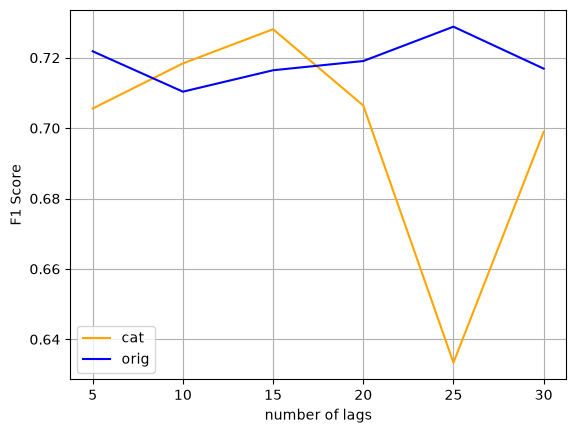

In [22]:
do_final_test(spb_df, best_model, drop_time = False)

draw_model_stats(history)

In [23]:
# Path("models").mkdir(parents=True, exist_ok=True)

# with open(f'models/{mode}_model.pkl', 'wb') as f:
#     pickle.dump(best_model["Model"], f)